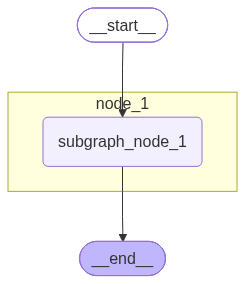

In [2]:
from IPython.core.display import Image
from langgraph.graph.state import START, StateGraph
from typing_extensions import TypedDict


class SubgraphState(TypedDict):
    bar: str


# Subgraph


def subgraph_node_1(state: SubgraphState):
    return {"bar": "hi! " + state["bar"]}


subgraph_builder = StateGraph(SubgraphState)
subgraph_builder.add_node(subgraph_node_1)
subgraph_builder.add_edge(START, "subgraph_node_1")
subgraph = subgraph_builder.compile()

# Parent graph


class State(TypedDict):
    foo: str


def call_subgraph(state: State):
    # Transform the state to the subgraph state
    subgraph_output = subgraph.invoke({"bar": state["foo"]})
    # Transform response back to the parent state
    return {"foo": subgraph_output["bar"]}


builder = StateGraph(State)
builder.add_node("node_1", call_subgraph)
builder.add_edge(START, "node_1")
graph = builder.compile()
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

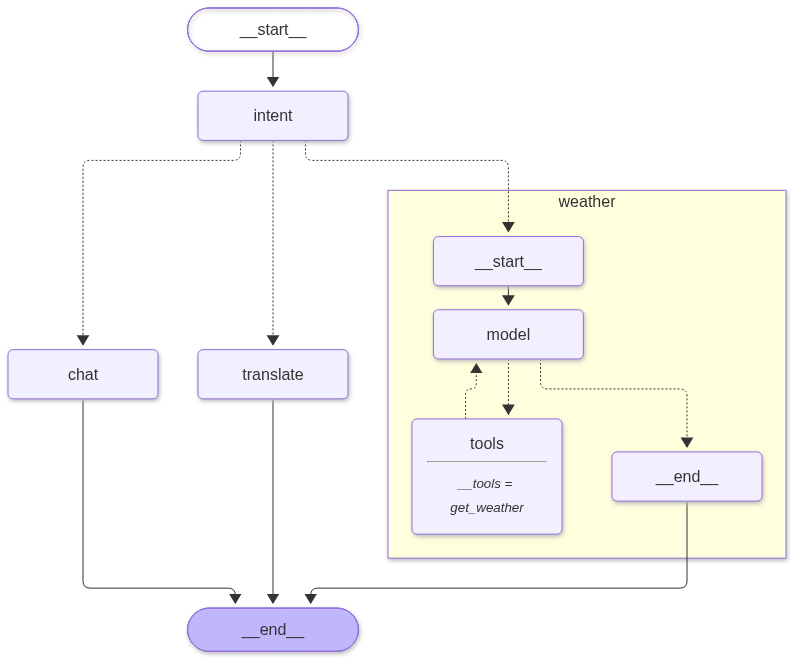

'今天北京天气如何？' -> intent=weather -> 今天北京天气是晴天，气温约25度，适合外出活动。
'倍儿爽用英文怎么说' -> intent=translate -> “倍儿爽” can be translated as “awesome,” “super refreshing,” or “feels great” depending on context.
'你好' -> intent=chat -> 你好！很高兴见到你，有什么我可以帮忙的吗？无论是聊天、解答问题，还是需要一些建议，我都很乐意提供帮助！😊


In [6]:
from typing import Literal

from IPython.core.display import Image
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langgraph.constants import END, START
from langgraph.graph import MessagesState, StateGraph

# https://docs.langchain.com/oss/python/langgraph/workflows-agents

# ===============Step 1: 初始化chat模型===============
llm = init_chat_model("deepseek-v4-flash", extra_body={"thinking": {"type": "disabled"}})


# ===============Step 2: 定义State，记录用户输入、最终结果===============
# 父 State
class IntentState(MessagesState):
    intent: str  # 意图


# 子 State
class WeatherState(MessagesState):
    foo: str  # 故意展示与父不同的字段


# ====== Step 1: 准备工具 ======
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")


# 组成工具数组
tools = [get_weather]

# ====== Step 3: 定义Agent ======
weather_agent = create_agent(llm, tools)


# response = weather_agent.invoke({"messages":[HumanMessage("杭州今天天气如何？")]})
# rich_print(response)
# ===============Step 4: 定义Node===============
def intent_node(state: IntentState):
    intent = llm.invoke(f"""
    根据用户的请求判断用户意图，可选意图：weather、translate或chat。
    user_query: {state["messages"][-1].content}
    """)
    return {"intent": intent.content}


def translate_node(state: IntentState):
    result = llm.invoke(f"""
    按照用户要求翻译，只输出翻译结果，不要任何解释。
    user_query:{state["messages"][-1].content}
    """)
    return {"messages": [result]}


def chat_node(state: IntentState):
    result = llm.invoke(state["messages"])
    return {"messages": [result]}


def intent_router(state: IntentState) -> Literal["weather", "translate", "chat"]:
    """根据意图路由到不同处理器"""
    return state["intent"]


# ===============Step 5: 创建Graph===============
builder = StateGraph(IntentState)
builder.add_node("intent", intent_node)
builder.add_node("weather", weather_agent)
builder.add_node("chat", chat_node)
builder.add_node("translate", translate_node)

builder.add_edge(START, "intent")
builder.add_conditional_edges("intent", intent_router)
builder.add_edge("weather", END)
builder.add_edge("chat", END)
builder.add_edge("translate", END)

routing_graph = builder.compile()
display(Image(routing_graph.get_graph(xray=True).draw_mermaid_png()))

for q in ["今天北京天气如何？", "倍儿爽用英文怎么说", "你好"]:
    r = routing_graph.invoke({"messages": [HumanMessage(content=q)]})
    print(f"'{q}' -> intent={r['intent']} -> {r['messages'][-1].content}")